<a href="https://colab.research.google.com/github/Sahana14082003/ADSA/blob/main/Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter number of keys: 7
Enter the keys separated by spaces: 23 76 89 99 12 6 8 
Prime used for double hashing: 11

HASH TABLE
-------------------------------------------------------------------------------------
Index   Chaining          Linear Probing    Quadratic Probing   Double Hashing
-------------------------------------------------------------------------------------
0       []                12                12                  None
1       []                None              None                8
2       []                None              None                None
3       []                None              None                6
4       []                None              None                None
5       []                None              None                None
6       [6]               6                 6                   99
7       []                None              None                None
8       [8, 99]           99                99                  89
9       []  

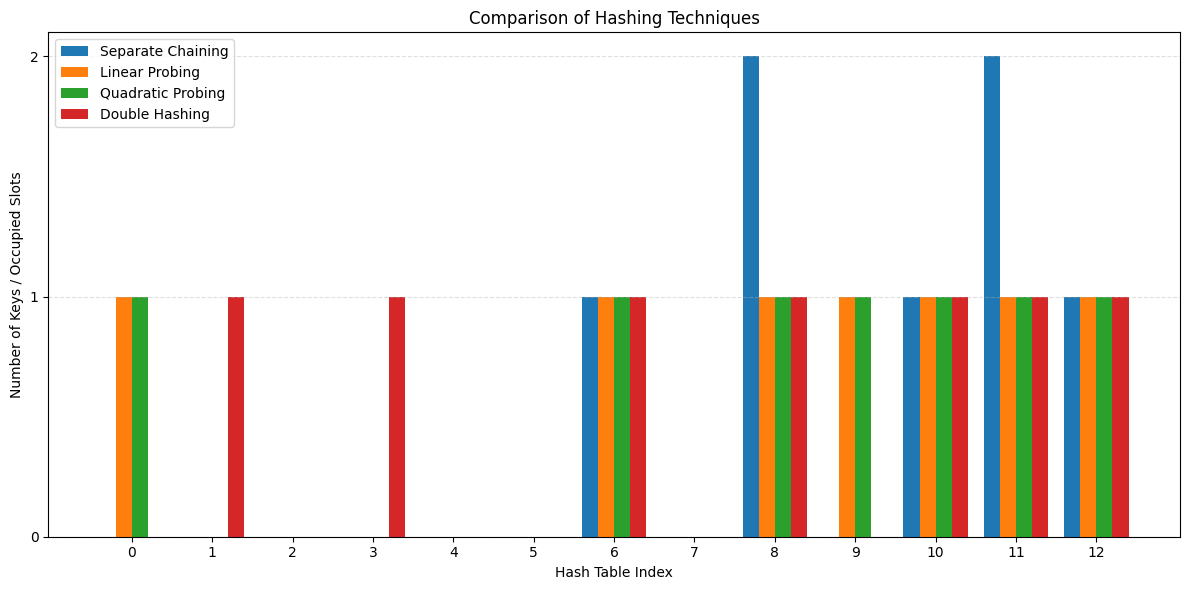

In [1]:

import matplotlib.pyplot as plt
import numpy as np

SIZE = 13

# Function to check whether a number is prime
def is_prime(n):
    if n < 2:
        return False

    for i in range(2, int(n ** 0.5) + 1):
        if n % i == 0:
            return False

    return True


# Function to find the largest prime smaller than table size
def find_prime(size):
    for n in range(size - 1, 1, -1):
        if is_prime(n):
            return n
    return None


# Input
n = int(input("Enter number of keys: "))
keys = list(map(int, input("Enter the keys separated by spaces: ").split()))

if n <= 0 or len(keys) != n:
    print("Error: Please enter the correct number of keys.")

else:
    # Separate Chaining
    chaining = [[] for _ in range(SIZE)]

    for key in keys:
        chaining[key % SIZE].insert(0, key)

    # Linear Probing
    linear = [None] * SIZE

    for key in keys:
        index = key % SIZE

        for i in range(SIZE):
            if linear[index] is None:
                linear[index] = key
                break
            index = (index + 1) % SIZE

    # Quadratic Probing
    quadratic = [None] * SIZE

    for key in keys:
        h = key % SIZE

        for i in range(SIZE):
            index = (h + i * i) % SIZE

            if quadratic[index] is None:
                quadratic[index] = key
                break

    # Double Hashing
    double = [None] * SIZE
    prime = find_prime(SIZE)

    print("Prime used for double hashing:", prime)

    for key in keys:
        h1 = key % SIZE
        h2 = prime - (key % prime)

        for i in range(SIZE):
            index = (h1 + i * h2) % SIZE

            if double[index] is None:
                double[index] = key
                break

    # Display all hash tables
    print("\nHASH TABLE")
    print("-" * 85)

    print(f"{'Index':<8}{'Chaining':<18}{'Linear Probing':<18}"
          f"{'Quadratic Probing':<20}{'Double Hashing'}")

    print("-" * 85)

    for i in range(SIZE):
        print(f"{i:<8}{str(chaining[i]):<18}{str(linear[i]):<18}"
              f"{str(quadratic[i]):<20}{str(double[i])}")

    # Bar Graph
    indices = list(range(SIZE))

    chaining_count = [len(bucket) for bucket in chaining]
    linear_count = [0 if value is None else 1 for value in linear]
    quadratic_count = [0 if value is None else 1 for value in quadratic]
    double_count = [0 if value is None else 1 for value in double]

    x = np.arange(SIZE)
    width = 0.2

    plt.figure(figsize=(12, 6))

    plt.bar(x - 1.5 * width, chaining_count, width,
            label="Separate Chaining")
    plt.bar(x - 0.5 * width, linear_count, width,
            label="Linear Probing")
    plt.bar(x + 0.5 * width, quadratic_count, width,
            label="Quadratic Probing")
    plt.bar(x + 1.5 * width, double_count, width,
            label="Double Hashing")

    plt.xlabel("Hash Table Index")
    plt.ylabel("Number of Keys / Occupied Slots")
    plt.title("Comparison of Hashing Techniques")

    plt.xticks(x, indices)
    plt.yticks([0, 1, 2])
    plt.legend()
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()
